# Lab 3: Your First End-to-End Pipeline

**Time:** about 75 minutes

In Lab 2 you explored the data by hand, one cell at a time. That's the right way to *learn* a dataset, and
the wrong way to *process* it every month. Next month there'll be a new extract, and you want to run one
command and get clean tables, charts and a quality report, not repeat the whole afternoon.

In this lab you'll turn your findings into a small pipeline with clear stages:

```
 raw CSVs ──► load ──► clean ──► validate ──► transform ──► outputs
                                    │                         ├─ processed Parquet tables
                                    └─► validation report     ├─ standard charts
                                                              └─ profile report
```

You'll build every stage step by step in this notebook first. Then you'll copy the same steps into a script,
`src/fund_pipeline.py`, run it from the terminal, and prove that it gives the same result every time.

The rule for the whole lab: **the raw files are never changed.** Every stage reads something and writes
something new.

## Where this lab fits

**What you've done so far.** In Lab 1 you set up your environment and Git. In Lab 2 you explored the four raw tables
by hand and wrote an **issues log**: duplicate members, double postings and reversals, payment dates in the 2200s,
birth dates 30 years out, five spellings of Dar es Salaam, probable wage typing errors, claims for unknown members.

**What you'll do now.** You'll turn every line of that issues log into code that runs in a fixed order, from the raw
files to clean tables, charts and a quality report. First you'll build each step in this notebook, so you can see what
it does. Then you'll move the same steps into a script and prove it gives the same result every time it runs.

**Why it matters.** Lab 2's notebook answered "what's wrong with *this* extract?". The Fund gets a new extract every
month. If cleaning depends on someone remembering forty manual steps, it'll be done slightly differently each time,
and the numbers in reports won't agree. A pipeline makes cleaning **repeatable** (same steps every time),
**checkable** (it reports what it changed) and **shareable** (anyone can run it).

**What happens next.** From Day 2 onwards, every model starts from clean data like the data this pipeline produces.
On Day 3 you'll add version control for the data itself (DVC), and on Day 10 you'll see the same ideas in a deployed
service.

### Theory: what a data pipeline is

A **pipeline** is a series of **stages**, where each stage takes the output of the one before:

| Stage | Question it answers | Output |
|---|---|---|
| **Load** | Can we read the files, with the right types? | raw tables in memory |
| **Clean** | Which known problems can we fix safely? | clean tables, with flag columns |
| **Validate** | Does the clean data obey the business rules? | a pass/fail report; stop if a serious rule fails |
| **Transform** | What extra fields do people need? | ages, days late, penalty estimates |
| **Outputs** | How do people get the results? | Parquet files, charts, a profile |

Three principles run through the whole lab:

1. **Never change the raw data.** Each stage reads one thing and writes something new. If a rule turns out to be
   wrong, you fix the rule and rerun; the original is still there.
2. **Say what you changed.** Every cleaning step prints how many rows it touched. A step that silently changes 30% of
   the rows is a step nobody can trust.
3. **Flag what you can't be sure of.** If the code can't know the right answer (is that wage a typo or a director?),
   it adds a True/False **flag column** for a person to look at, rather than guessing.

In [103]:
# Libraries for this lab.
import hashlib        # to fingerprint files (Section 12)
import subprocess     # to run the pipeline script from the notebook (Section 11)
import sys
import time           # to time how long things take
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [104]:
# Where the raw CSV files are. With the Lab 1 layout they're in ../data/raw, otherwise next to this notebook.
RAW = Path("../data/raw")
if not (RAW / "members.csv").exists():
    RAW = Path(".")

# Where this notebook writes its outputs.
OUT = Path("output")
OUT.mkdir(exist_ok=True)

# The date the extract was taken.
SNAPSHOT = pd.Timestamp("2026-01-31")

print("raw data:", RAW.resolve())
print("outputs: ", OUT.resolve())

raw data: /Users/daud.mabena/Documents/DUBAI/Training1910Labs/DAY1/Labs/work/fund-ai/data/raw
outputs:  /Users/daud.mabena/Documents/DUBAI/Training1910Labs/DAY1/Labs/work/fund-ai/notebooks/output


### Theory: memory, number types, and precision

Your laptop holds the data you're working on in **RAM** (memory). If a table needs more memory than you have, Python
slows to a crawl or crashes. Today's files are small, but Day 3's member-level history is millions of rows, so it's
worth learning the habits now.

**How much memory a column needs** depends on its type and the number of rows:

| Type | Bytes per value | Range | For 1 million rows |
|---|---|---|---|
| `int64` | 8 | about ±9 quintillion | 8 MB |
| `int32` | 4 | about ±2.1 billion | 4 MB |
| `int16` | 2 | -32,768 to 32,767 | 2 MB |
| `float64` | 8 | about 15-16 significant digits | 8 MB |
| `float32` | 4 | about 7 significant digits | 4 MB |
| text (`object`) | 50 or more | anything | 50+ MB |
| `category` | 1-2, plus the list of values once | a fixed set of values | 1-2 MB |

pandas picks the biggest, safest type unless you tell it otherwise. Choosing smaller types is called **downcasting**.

**Significant digits.** A `float32` stores about 7 significant digits, which means it can hold 1,234,567 exactly but
not 123,456,789: it rounds to the nearest number it can store. For money in shillings, where amounts run into the
billions, those rounding errors add up in totals. So the rule in this lab is: shrink counts and labels, keep money as
`float64`.

## 1. Larger data on a laptop

The contributions file is the biggest one here, but it's still small. The full member-level history
on Day 3 is millions of rows. Before writing the pipeline, a few habits that keep memory under control.

### Measure first

In [169]:
# Read the file with no instructions: pandas guesses every type.
naive = pd.read_csv(RAW / "contributions_monthly.csv")
print(naive.dtypes)

employer_no                 str
period                      str
members_reported          int64
gross_wages_tzs         float64
contribution_due_tzs    float64
amount_paid_tzs         float64
due_date                    str
payment_date                str
dtype: object


In [170]:
# Memory used, in MB.
naive_mb = naive.memory_usage(deep=True).sum() / 1e6
print(f"Memory with default types: {naive_mb:.1f} MB")

Memory with default types: 12.6 MB


By default pandas uses 64-bit numbers and generic text for everything. Most of these columns don't need
that:

- `employer_no` repeats about 90 times each, so it's a good `category`.
- `period` has 108 distinct values. Also a `category`.
- `members_reported` is never above a few thousand, so `int32` is plenty. (It can't be `int16` safely
  if a very large employer ever reports more than 32,767 staff, so don't squeeze too hard.)

In [171]:
# Tell pandas the type of each column.
contrib_dtypes = {
    "employer_no": "category",
    "period": "category",
    "members_reported": "int32",
    "gross_wages_tzs": "float64",
    "contribution_due_tzs": "float64",
    "amount_paid_tzs": "float64",
}

# parse_dates turns these two columns into real dates while reading.
typed = pd.read_csv(RAW / "contributions_monthly.csv", dtype=contrib_dtypes, parse_dates=["due_date", "payment_date"])

typed_mb = typed.memory_usage(deep=True).sum() / 1e6
print(f"Memory with chosen types: {typed_mb:.1f} MB")

Memory with chosen types: 6.1 MB


Money stays as `float64`. Downcasting amounts to `float32` saves memory but loses precision on large
shilling values. For a finance dataset that's a bad trade.

- `float32` keeps about 7 significant digits: TZS 123,456,789 may be stored as 123,456,792.
- `float64` keeps about 15-16 significant digits, enough for any amount the Fund handles.

### Chunked reading

When a file really is too big to load at once, read it in pieces and keep only the running totals.
Here's total contributions due per year, computed without ever holding the whole file in memory:

In [177]:
# A dictionary to hold the running total for each year, e.g. {"2024": 1.2e12, ...}
totals = {}

# chunksize=25_000 makes read_csv hand us the file 25,000 rows at a time.
reader = pd.read_csv(RAW / "contributions_monthly.csv", usecols=["period", "contribution_due_tzs"], chunksize=250000)

for chunk in reader:
    # The year is the first 4 characters of the period, e.g. "2024-03" -> "2024".
    chunk["year"] = chunk["period"].str[:4]

    # Total due per year, in this chunk only.
    chunk_totals = chunk.groupby("year")["contribution_due_tzs"].sum()

    # Add this chunk's totals to the running totals.
    for year in chunk_totals.index:
        if year not in totals:
            totals[year] = 0
        totals[year] = totals[year] + chunk_totals[year]

# Show the totals in TZS billions.
totals_billions = pd.Series(totals).sort_index() / 1e9
totals_billions

2017    38.040959
2018    41.942309
2019    47.121845
2020    50.170491
2021    55.293331
2022    61.420200
2023    70.679932
2024    76.343528
2025    82.649822
dtype: float64

Only one chunk of 25,000 rows is in memory at a time. Each is summarised, added to the running totals, and then
thrown away before the next one is read.

Chunking works for sums, counts and anything else you can add up piece by piece. It doesn't work for a
median or a sort over the whole file. That's where tools like Polars, Dask and Spark come in. You'll use Dask
on Day 3.

### CSV or Parquet?

Write the same table both ways, then read it back, timing each step.

In [178]:
# Write as CSV and time it.
start = time.perf_counter()
typed.to_csv(OUT / "_test.csv", index=False)
csv_write_seconds = time.perf_counter() - start

# Write as Parquet and time it.
start = time.perf_counter()
typed.to_parquet(OUT / "_test.parquet", index=False)
parquet_write_seconds = time.perf_counter() - start

print(f"write CSV:     {csv_write_seconds:.2f} s")
print(f"write Parquet: {parquet_write_seconds:.2f} s")

write CSV:     0.28 s
write Parquet: 0.03 s


In [179]:
# Read both back and time it.
start = time.perf_counter()
from_csv = pd.read_csv(OUT / "_test.csv")
csv_read_seconds = time.perf_counter() - start

start = time.perf_counter()
from_parquet = pd.read_parquet(OUT / "_test.parquet")
parquet_read_seconds = time.perf_counter() - start

print(f"read CSV:     {csv_read_seconds:.2f} s")
print(f"read Parquet: {parquet_read_seconds:.2f} s")

read CSV:     0.11 s
read Parquet: 0.03 s


In [180]:
# File sizes, in MB.
print(f"CSV size:     {(OUT / '_test.csv').stat().st_size / 1e6:.1f} MB")
print(f"Parquet size: {(OUT / '_test.parquet').stat().st_size / 1e6:.1f} MB")

# Did the column types survive? Compare the types read back with the originals.
print("\ntypes after reading the CSV:")
print(from_csv.dtypes)
print("\ntypes after reading the Parquet file:")
print(from_parquet.dtypes)

CSV size:     9.1 MB
Parquet size: 2.0 MB

types after reading the CSV:
employer_no                 str
period                      str
members_reported          int64
gross_wages_tzs         float64
contribution_due_tzs    float64
amount_paid_tzs         float64
due_date                    str
payment_date                str
dtype: object

types after reading the Parquet file:
employer_no                   category
period                        category
members_reported                 int32
gross_wages_tzs                float64
contribution_due_tzs           float64
amount_paid_tzs                float64
due_date                datetime64[us]
payment_date            datetime64[us]
dtype: object


In [112]:
# Delete the two test files.
(OUT / "_test.csv").unlink()
(OUT / "_test.parquet").unlink()

> **Where we are.** You've seen how to shrink a table's memory, read a file too big for memory in pieces, and why
> Parquet beats CSV for processed data. Now the pipeline itself begins, with its first stage.

### Theory: why Parquet is smaller and faster

A CSV stores data **row by row** as text. To read one column you still have to read every character of every row, and
every number has to be converted from text again.

**Parquet** stores data **column by column**, in binary (the computer's own format, not text):

```
CSV (rows):      E001,2024-01,42,8400000 \n E001,2024-02,43,8600000 \n ...
Parquet (cols):  [E001, E001, ...] [2024-01, 2024-02, ...] [42, 43, ...] [8400000, 8600000, ...]
```

That gives three advantages:

- **Smaller files.** Values in one column look alike, so they compress well. A column that repeats `E001` ninety times
  takes almost no space.
- **Faster reads.** No text to convert, and you can read just the columns you need.
- **Types are saved.** A date column comes back as a date and a category as a category. With CSV the next person has
  to redo all of that.

The usual habit in data teams: source systems give you CSV, and everything you produce is Parquet.

Parquet is smaller, faster to read, and remembers your column types (the CSV came back with `object` text and no
dates), so the next person doesn't have to redo them. From here on, raw data arrives as CSV (that's what source
systems usually export) and processed data is written as Parquet.

## 2. Load stage

Read each table with its ID columns as text and its date columns parsed. `parse_dates` converts the date columns
while reading. If a column contains a value that isn't a date, pandas quietly leaves the whole column as text, so check
the types after loading.

In [181]:
# Employers
employers_raw = pd.read_csv(
    RAW / "employers.csv",
    dtype={"employer_no": "string", "tin": "string"},
    parse_dates=["registration_date", "closure_date"],
)
print("loaded employers:", len(employers_raw), "rows")

loaded employers: 1408 rows


In [182]:
# Members
members_raw = pd.read_csv(
    RAW / "members.csv",
    dtype={"member_no": "string", "employer_no": "string", "nida_no": "string", "phone": "string"},
    parse_dates=["date_of_birth", "employment_start", "registration_date", "exit_date", "date_of_death"],
)
print("loaded members:", len(members_raw), "rows")

loaded members: 61016 rows


In [183]:
# Contributions
contrib_raw = pd.read_csv(
    RAW / "contributions_monthly.csv",
    dtype={"employer_no": "string", "period": "string", "members_reported": "int32"},
    parse_dates=["due_date", "payment_date"],
)
print("loaded contributions:", len(contrib_raw), "rows")

loaded contributions: 127902 rows


In [116]:
# Claims
claims_raw = pd.read_csv(
    RAW / "claims.csv",
    dtype={"claim_no": "string", "member_no": "string"},
    parse_dates=["claim_date", "decision_date"],
)
print("loaded claims:", len(claims_raw), "rows")
claims_raw[["claim_no", "member_no"]].head(900)

loaded claims: 13848 rows


,claim_no,member_no
0,CLM-2017-004967,460366954
1,CLM-2017-000309,432191244
2,CLM-2017-010038,240225973
3,CLM-2017-005931,371540847
4,CLM-2017-004652,413793900
...,...,...
895,CLM-2017-005343,120198748
896,CLM-2017-005488,384754688
897,CLM-2017-006624,148403644
898,CLM-2017-013693,518562119


In [184]:
# Check every date column really became a date (datetime64). If one is still "object", it had a bad value.
members_raw.dtypes

member_no                      string
first_name                        str
surname                           str
gender                            str
date_of_birth          datetime64[us]
nida_no                        string
phone                          string
region                            str
employer_no                    string
employment_start       datetime64[us]
registration_date      datetime64[us]
contribution_months             int64
exit_date              datetime64[us]
exit_reason                       str
date_of_death          datetime64[us]
status                            str
monthly_wage_tzs              float64
dtype: object

> **Where we are.** The four raw tables are loaded with the right types, and you've checked the row counts. They
> still have every problem you found in Lab 2. The clean stage fixes the ones that can be fixed safely.

### Theory: the order of cleaning steps matters

Cleaning steps aren't independent. Doing them in a different order can give a different answer. Two examples from
this data:

- **Phones before de-duplicating members.** The duplicate member rows differ only in the phone format (`+255...` vs
  `0...`). Standardise the phone first, and the two rows become identical, so keeping one of them loses nothing. Drop
  duplicates first, and you keep whichever phone format happens to come first.
- **Protect reversals before dropping exact duplicates.** A double posting followed by a reversal is three rows: +X, +X
  (identical to the first) and -X. Their total is +X, which is correct. If you drop exact duplicates first, you remove
  one +X and keep the -X, and the total becomes zero: the employer looks as if it paid nothing.

That's why each rule below is written down in a fixed order, and why the pipeline always runs them in that order.

**Working on a copy.** `employers = employers_raw.copy()` makes a separate table. Changes to `employers` don't touch
`employers_raw`, so you can always compare "before" and "after", which you'll do at the end of this section.

Notice the row counts printed after each load. When the pipeline runs unattended at night, those counts are how
you'll know whether last night's extract had 128,000 rows or 12.

## 3. Clean stage

Each rule below comes straight from your Lab 2 issues log. The cleaning steps:

- work on a **copy**, so the raw table is never modified,
- print what they changed,
- add a **flag column** rather than silently "fixing" things they can't be sure about.

### Employers

In [185]:
# Work on a copy.
employers = employers_raw.copy()

# Remove stray spaces from the names.
employers["employer_name"] = employers["employer_name"].str.strip()

In [186]:
# The region spellings to correct (the same dictionary as in Lab 2).
REGION_FIX = {
    "dsm": "Dar es Salaam",
    "dar es salaam": "Dar es Salaam",
    "dar-es-salaam": "Dar es Salaam",
}


def clean_region(region_column):
    """Trim spaces, fix the Dar es Salaam spellings, and title-case every other region."""
    region = region_column.str.strip().str.lower()
    region = region.replace(REGION_FIX)
    is_dar = region == "Dar es Salaam"
    region[~is_dar] = region[~is_dar].str.title()
    return region


employers["region"] = clean_region(employers["region"])
employers["region"].value_counts().head()


region
Dar es Salaam    435
Arusha           115
Mwanza           104
Dodoma            87
Mbeya             82
Name: count, dtype: int64

In [187]:
# Keep one row per employer. Sorting by name first means the same row is kept every time we run.
rows_before = len(employers)
employers = employers.sort_values("employer_name")
employers = employers.drop_duplicates(subset=["employer_no"], keep="first")
employers = employers.reset_index(drop=True)
print("clean employers: dropped", rows_before - len(employers), "duplicate rows")

clean employers: dropped 8 duplicate rows


### Members

In [188]:
# Work on a copy, and clean the region the same way.
members = members_raw.copy()
members["region"] = clean_region(members["region"])

In [189]:
# Gender: trim, upper case, first letter only. Anything other than F or M becomes missing.
gender = members["gender"].str.strip().str.upper().str[0]
gender[~gender.isin(["F", "M"])] = np.nan
members["gender"] = gender
members["gender"].value_counts(dropna=False)

gender
M      34860
F      25424
NaN      732
Name: count, dtype: int64

In [123]:
def normalize_phone(phone):
    """Make every phone number look like +255712345678."""
    # Phone numbers come as "+255 712 345 678", "0712345678", ... Make them all "+255712345678".
    # Step 1: keep only the digits. The pattern \D means "any character that is not a digit".
    phone = phone.str.replace(r"\D", "", regex=True)

    # Step 2: a number starting with 0 is a local number: swap the leading 0 for the country code 255.
    phone = phone.str.replace(r"^0", "255", regex=True)

    # Step 3: put a + in front.
    return "+" + phone


members["phone"] = normalize_phone(members["phone"])
members["phone"].head()

0    +255745819586
1    +255715886482
2    +255725141381
3    +255722922685
4    +255775690476
Name: phone, dtype: string

In [124]:
# With phones in one format, the duplicate member rows are now identical. Keep one row per member_no.
rows_before = len(members)
members = members.drop_duplicates(subset=["member_no"], keep="first")
members = members.reset_index(drop=True)
print("clean members: dropped", rows_before - len(members), "duplicate rows")
members["member_no"].head(900)

clean members: dropped 120 duplicate rows


0      108636731
1      159131551
2      253383084
3      217744457
4      468769855
         ...    
895    507197906
896    322723125
897    163246844
898    221355671
899    118892002
Name: member_no, Length: 900, dtype: string

In [125]:
# Flag 1: birth dates that make the member younger than 15 at registration.
age_at_registration = (members["registration_date"] - members["date_of_birth"]).dt.days / 365.25
members["flag_implausible_dob"] = age_at_registration < 15

# We can't know the right date, so set the wrong ones to missing (NaT = "not a time").
members.loc[members["flag_implausible_dob"], "date_of_birth"] = pd.NaT
print("implausible birth dates set to missing:", members["flag_implausible_dob"].sum())

implausible birth dates set to missing: 20


In [126]:
# Flag 2: wages 8 or more times the median wage at the same employer.
employer_median = members.groupby("employer_no")["monthly_wage_tzs"].transform("median")
members["flag_wage_outlier"] = members["monthly_wage_tzs"] > 8 * employer_median

# We flag these for a person to check. We do NOT change the wage.
print("wage outliers flagged:", members["flag_wage_outlier"].sum())


wage outliers flagged: 10


### Contributions

The contributions table needs the careful rule from Lab 2. The order matters:

1. For an employer-month that contains a **negative** amount, keep every row. It's a posting, a double
   posting and a reversal, and adding them up gives the right total.
2. For every other employer-month, drop exact duplicate rows (extraction duplicates).
3. Then combine to one row per employer-month.

In [127]:
contrib = contrib_raw.copy()

# A single text key for each employer-month, e.g. "E00123|2024-03". Easier to work with than two columns.
contrib["month_key"] = contrib["employer_no"] + "|" + contrib["period"]

# The keys of the employer-months that contain a negative amount (a reversal).
negative_rows = contrib["amount_paid_tzs"] < 0
reversal_keys = contrib.loc[negative_rows, "month_key"].unique()
print("employer-months with a reversal:", len(reversal_keys))

employer-months with a reversal: 25


In [128]:
# Rule 1: rows from those employer-months are kept exactly as they are.
has_reversal = contrib["month_key"].isin(reversal_keys)
keep_as_is = contrib[has_reversal]

# Rule 2: every other row, with exact duplicates removed.
others = contrib[~has_reversal].drop_duplicates()

# Put the two parts back together.
rows_before = len(contrib)
contrib = pd.concat([keep_as_is, others])
print("clean contributions: dropped", rows_before - len(contrib), "exact duplicate rows")

clean contributions: dropped 509 exact duplicate rows


In [129]:
# Payment dates after the snapshot are typing errors (2205 for 2025). Flag them, then set them to missing.
contrib["future_date_fixed"] = contrib["payment_date"] > SNAPSHOT
contrib.loc[contrib["future_date_fixed"], "payment_date"] = pd.NaT
print("payment dates after the snapshot set to missing:", contrib["future_date_fixed"].sum())

payment dates after the snapshot set to missing: 10


In [130]:
# Rule 3: one row per employer-month. For each column, say how to combine the rows of one month:
#   "first" - take the first value (the schedule columns are the same on every row)
#   "sum"   - add the payments up (posting + double posting + reversal = the real amount)
#   "min"   - the earliest payment date
#   "count" - how many payment rows had an amount
#   "size"  - how many rows there were in total
#   "max"   - True if any row was True
contrib = contrib.groupby(["employer_no", "period"], as_index=False).agg(
    members_reported=("members_reported", "first"),
    gross_wages_tzs=("gross_wages_tzs", "first"),
    contribution_due_tzs=("contribution_due_tzs", "first"),
    due_date=("due_date", "first"),
    amount_paid_tzs=("amount_paid_tzs", "sum"),
    payment_date=("payment_date", "min"),
    n_amounts=("amount_paid_tzs", "count"),
    n_postings=("amount_paid_tzs", "size"),
    future_date_fixed=("future_date_fixed", "max"),
)

# "sum" turns a month with no payment at all into 0. It should stay missing (unpaid), so put the gap back.
contrib.loc[contrib["n_amounts"] == 0, "amount_paid_tzs"] = np.nan
contrib = contrib.drop(columns=["n_amounts"])

print("rows after combining:", len(contrib))

rows after combining: 127343


In [131]:
# Missing gross wages can be worked out: the contribution due is 20% of gross wages, so wages = due / 0.20.
missing_wages = contrib["gross_wages_tzs"].isna()
contrib.loc[missing_wages, "gross_wages_tzs"] = contrib.loc[missing_wages, "contribution_due_tzs"] / 0.20
print("missing gross wages derived from the amount due:", missing_wages.sum())

missing gross wages derived from the amount due: 764


### Claims

In [132]:
# Benefit type: trim, upper case, spaces to underscores ("Old Age Pension" -> "OLD_AGE_PENSION").
claims = claims_raw.copy()
claims["benefit_type"] = claims["benefit_type"].str.strip().str.upper().str.replace(" ", "_")
claims["benefit_type"].value_counts()

benefit_type
UNEMPLOYMENT          7923
MATERNITY             3784
OLD_AGE_PENSION       1122
OLD_AGE_GRANT          291
SURVIVORS_PENSION      271
FUNERAL_GRANT          265
INVALIDITY_PENSION     122
EMPLOYMENT_INJURY       70
Name: count, dtype: int64

Check the reversal rule did what you meant. Pick an employer-month that had a reversal and compare raw
and clean:

In [133]:
# The first negative payment in the raw data, and its employer and period.
first_reversal = contrib_raw[contrib_raw["amount_paid_tzs"] < 0].iloc[0]
emp = first_reversal["employer_no"]
period = first_reversal["period"]
print("employer", emp, "period", period)

employer ER366966 period 2018-06


In [134]:
# Raw rows for that employer-month.
same_month_raw = (contrib_raw["employer_no"] == emp) & (contrib_raw["period"] == period)
contrib_raw.loc[same_month_raw, ["amount_paid_tzs", "payment_date"]]

,amount_paid_tzs,payment_date
2313,-134400.0,2018-09-17
36866,134400.0,2018-09-08
100209,134400.0,2018-09-08


In [135]:
# The clean row for the same employer-month.
same_month_clean = (contrib["employer_no"] == emp) & (contrib["period"] == period)
contrib.loc[same_month_clean, ["contribution_due_tzs", "amount_paid_tzs", "n_postings"]]

,contribution_due_tzs,amount_paid_tzs,n_postings
74955,134400.0,134400.0,3


### Theory: validation, and the difference between a stop and a warning

**Cleaning** fixes problems you know about. **Validation** checks that the result obeys the rules it must obey, so you
catch problems you *didn't* know about: a new kind of error in next month's extract, or a bug in your own cleaning
code.

A validation rule is a yes/no question asked of every row: *"is this member number unique?"*, *"is this payment date on
or before the snapshot?"*. Counting the rows that answer "no" gives the number of failures.

Rules come in two strengths, and choosing the right one for each rule is a judgement call:

| | Hard rule | Soft rule |
|---|---|---|
| Meaning | the data is broken | a record needs a person's attention |
| Example | the same `member_no` twice after cleaning | a claim lodged after the member's recorded death |
| What the pipeline does | **stops with an error** | carries on, and lists the failures in the report |
| Why | every number downstream would be wrong | the data is usable; the case still needs checking |

Stopping might sound drastic, but a pipeline that stops loudly is far better than one that carries on and puts wrong
totals into a board report. In Python, stopping is done by **raising an exception**: `raise ValueError("...")` ends
the run with your message.

Three postings in, one row out, and the amount paid counts the payment once, not twice. The raw table still
has all three rows, untouched.

## 4. Validate stage: business rules as code

In Lab 2 you *looked* for problems. Now write them down as rules that run every time. There are two kinds:

- **Hard rules.** If one fails, the data is broken and the pipeline must stop, for example duplicate keys
  after cleaning. Continuing would produce wrong numbers downstream.
- **Soft rules.** They find records a person should look at, like a claim after a recorded death. The
  pipeline carries on, and the failures go into a report.

Each rule is one line that counts the rows breaking it. Start with the hard rules:

In [136]:
# Hard rules: each must have 0 failures.
fail_member_unique = members["member_no"].duplicated().sum()
fail_month_unique = contrib.duplicated(subset=["employer_no", "period"]).sum()
fail_claim_unique = claims["claim_no"].duplicated().sum()
fail_negative_net = (contrib["amount_paid_tzs"] < 0).sum()
fail_future_dates = (contrib["payment_date"] > SNAPSHOT).sum()

print("member_no unique:               ", fail_member_unique)
print("employer-month unique:          ", fail_month_unique)
print("claim_no unique:                ", fail_claim_unique)
print("no negative net contributions:  ", fail_negative_net)
print("no payment dates after snapshot:", fail_future_dates)

member_no unique:                0
employer-month unique:           0
claim_no unique:                 0
no negative net contributions:   0
no payment dates after snapshot: 0


In [137]:
# Soft rules need member details on each claim, so join them first.
claims_with_member = claims.merge(
    members[["member_no", "date_of_death", "gender"]], on="member_no", how="left"
)

PERSONAL_BENEFITS = ["MATERNITY", "UNEMPLOYMENT", "OLD_AGE_PENSION", "OLD_AGE_GRANT", "INVALIDITY_PENSION"]

In [138]:
# Soft rules: failures go to a person to review.
fail_unknown_member = (~claims["member_no"].isin(members["member_no"])).sum()

is_personal = claims_with_member["benefit_type"].isin(PERSONAL_BENEFITS)
after_death = claims_with_member["claim_date"] > claims_with_member["date_of_death"]
fail_after_death = (is_personal & after_death).sum()

is_maternity = claims_with_member["benefit_type"] == "MATERNITY"
fail_maternity_male = (is_maternity & (claims_with_member["gender"] == "M")).sum()

is_funeral = claims["benefit_type"] == "FUNERAL_GRANT"
fail_funeral_amount = (is_funeral & (claims["amount_claimed_tzs"] != 500_000)).sum()

fail_overpaid = (contrib["amount_paid_tzs"] > 1.15 * contrib["contribution_due_tzs"]).sum()

print("claim references a known member:        ", fail_unknown_member)
print("personal claim not after recorded death:", fail_after_death)
print("maternity claim by female member:       ", fail_maternity_male)
print("funeral grant equals TZS 500,000:       ", fail_funeral_amount)
print("paid not above due by more than 15%:    ", fail_overpaid)

claim references a known member:         35
personal claim not after recorded death: 24
maternity claim by female member:        10
funeral grant equals TZS 500,000:        6
paid not above due by more than 15%:     0


In [139]:
# Put every rule in one report table.
report = pd.DataFrame(
    [
        ["member_no unique", "hard", fail_member_unique],
        ["employer-month unique", "hard", fail_month_unique],
        ["claim_no unique", "hard", fail_claim_unique],
        ["no negative net contributions", "hard", fail_negative_net],
        ["no payment dates after snapshot", "hard", fail_future_dates],
        ["claim references a known member", "soft", fail_unknown_member],
        ["personal claim not after recorded death", "soft", fail_after_death],
        ["maternity claim by female member", "soft", fail_maternity_male],
        ["funeral grant equals TZS 500,000", "soft", fail_funeral_amount],
        ["paid not above due by more than 15%", "soft", fail_overpaid],
    ],
    columns=["rule", "severity", "failures"],
)

# Status: "pass" if no failures; otherwise "FAIL" for a hard rule and "review" for a soft one.
report["status"] = "pass"
report.loc[(report["failures"] > 0) & (report["severity"] == "soft"), "status"] = "review"
report.loc[(report["failures"] > 0) & (report["severity"] == "hard"), "status"] = "FAIL"
report

,rule,severity,failures,status
0,member_no unique,hard,0,pass
1,employer-month unique,hard,0,pass
2,claim_no unique,hard,0,pass
3,no negative net contributions,hard,0,pass
4,no payment dates after snapshot,hard,0,pass
5,claim references a known member,soft,35,review
6,personal claim not after recorded death,soft,24,review
7,maternity claim by female member,soft,10,review
8,"funeral grant equals TZS 500,000",soft,6,review
9,paid not above due by more than 15%,soft,0,pass


In [190]:
# Enforce the hard rules: if any hard rule failed, stop with an error.
hard_failures = report[report["status"] == "FAIL"]

if len(hard_failures) > 0:
    raise ValueError("Hard validation rules failed:\n" + hard_failures.to_string(index=False))

print("validation: all hard rules passed;", (report["status"] == "review").sum(), "soft rules need review")

validation: all hard rules passed; 4 soft rules need review


**Your turn (1).** See what happens when a hard rule fails. Run the `member_no unique` check on the *raw*
members table (`members_raw`) instead of the cleaned one, and stop with a `ValueError` if it fails, the same way as
the cell above. Wrap the check in `try: ... except ValueError as e: print(e)` so the notebook keeps running.

In [191]:
try:
    raw_duplicates = members_raw["member_no"].duplicated().sum()
    if raw_duplicates > 0:
        raise ValueError(f"Hard validation rule failed: member_no unique ({raw_duplicates} duplicates)")
    print("passed")
except ValueError as e:
    print(e)

Hard validation rule failed: member_no unique (120 duplicates)


> **Where we are.** The data is clean, and it has passed every hard rule. The soft-rule failures are listed for
> people to check. Now you'll add the fields people actually ask for.

### Theory: derived fields, and rules that change over time

A **derived field** is a new column worked out from existing ones: age from date of birth, days late from the due date
and payment date. Raw data records *what happened*; derived fields answer the *questions people ask*. Computing them
once, in the pipeline, means everyone uses the same definition. If finance and compliance each worked out "days late"
their own way, their reports would disagree.

**Business rules have dates.** The late-payment penalty was 5% per month until a circular changed it to 2.5% (with a
cap) from 1 October 2025. A contribution that was due in 2024 must still be charged under the old rule. So the code
doesn't ask "what's the rule?", it asks "what was the rule **on the date this contribution was due**?". You'll meet this
same circular again on Day 9, where an AI assistant has to get it right.

## 5. Transform stage: fields people actually ask for

Raw tables answer "what was recorded". Derived fields answer the questions people bring you: How old? How
long a member? How late? How much penalty?

### Members

In [192]:
# Age at the snapshot, in years, to one decimal place.
members["age"] = ((SNAPSHOT - members["date_of_birth"]).dt.days / 365.25).round(1)

# Years with the current employer. Members who haven't left are counted up to the snapshot date.
end_date = members["exit_date"].fillna(SNAPSHOT)
members["tenure_years_current_employer"] = ((end_date - members["employment_start"]).dt.days / 365.25).round(1)

# Registered more than 30 days after starting the job?
members["registered_late"] = (members["registration_date"] - members["employment_start"]).dt.days > 30

members[["member_no", "age", "tenure_years_current_employer", "registered_late"]].head()

,member_no,age,tenure_years_current_employer,registered_late
0,108636731,56.6,33.9,False
1,159131551,41.2,0.1,False
2,253383084,31.6,7.6,False
3,217744457,21.8,1.7,False
4,468769855,39.7,7.2,False


### Contributions

The late-payment penalty is a good example of a business rule that changes over time. The handbook says
5% per month or part of a month. Circular FC/09/2025 (you'll meet it again on Day 9) cut it to 2.5% with a
50% cap from 1 October 2025. The pipeline has to apply the rule that was in force at the time.

In [196]:
# The first day of the wage month, as a date: "2024-03" -> 2024-03-01.
contrib["period_start"] = pd.to_datetime(contrib["period"] + "-01")

# Days late. Unpaid months are counted up to the snapshot. clip(lower=0): paying early counts as 0 days late.
settled_date = contrib["payment_date"].fillna(SNAPSHOT)
contrib["days_late"] = (settled_date - contrib["due_date"]).dt.days.clip(lower=0)

# "Each month or part of a month": 1 to 30 days late = 1 month, 31 to 60 = 2 months, and so on.
# np.ceil rounds UP to the next whole number.
contrib["months_late"] = np.ceil(contrib["days_late"] / 30).astype(int)

# Amount still unpaid (never below zero). An unpaid month counts as 0 paid.
contrib["unpaid_tzs"] = (contrib["contribution_due_tzs"] - contrib["amount_paid_tzs"].fillna(0)).clip(lower=0)

contrib[["period", "due_date", "payment_date", "days_late", "months_late", "unpaid_tzs"]].head()

,period,due_date,payment_date,days_late,months_late,unpaid_tzs
0,2017-01,2017-02-28,2017-02-24,0,0,0.0
1,2017-02,2017-03-31,2017-03-12,0,0,0.0
2,2017-03,2017-04-30,2017-04-27,0,0,0.0
3,2017-04,2017-05-31,2017-05-09,0,0,0.0
4,2017-05,2017-06-30,2017-06-24,0,0,0.0


In [197]:
# Penalty rate: 5% under the old rule, 2.5% for contributions due from 1 October 2025.
contrib["penalty_rate"] = 0.05
new_rule = contrib["due_date"] >= pd.Timestamp("2025-10-01")
contrib.loc[new_rule, "penalty_rate"] = 0.025

# Penalty = amount due x rate x months late.
contrib["penalty_estimate_tzs"] = contrib["contribution_due_tzs"] * contrib["penalty_rate"] * contrib["months_late"]

# Under the new rule the penalty can't be more than 50% of the amount due.
cap = 0.5 * contrib["contribution_due_tzs"]
over_cap = new_rule & (contrib["penalty_estimate_tzs"] > cap)
contrib.loc[over_cap, "penalty_estimate_tzs"] = cap[over_cap]

# Round to the nearest 100 shillings.
contrib["penalty_estimate_tzs"] = contrib["penalty_estimate_tzs"].round(-2)

In [198]:
# Contribution per member reported. Avoid dividing by zero: treat 0 members as missing.
members_reported = contrib["members_reported"].replace(0, np.nan)
contrib["contribution_per_member_tzs"] = (contrib["contribution_due_tzs"] / members_reported).round(0)

# A random sample of 6 rows to check the results.
contrib[["employer_no", "period", "contribution_due_tzs", "payment_date", "months_late", "penalty_estimate_tzs"]].sample(6, random_state=1)

,employer_no,period,contribution_due_tzs,payment_date,months_late,penalty_estimate_tzs
122841,ER541689,2021-04,452600.0,2021-06-19,1,22600.0
81188,ER391346,2017-08,932400.0,2017-10-08,1,46600.0
11024,ER139981,2024-11,670400.0,2024-12-29,0,0.0
104215,ER477822,2017-10,547200.0,2017-11-26,0,0.0
81459,ER391931,2023-10,801200.0,2023-11-29,0,0.0
84413,ER402519,2018-02,1643400.0,2018-03-17,0,0.0


Pause on `penalty_estimate_tzs` for a moment. The column name says *estimate*, and that's deliberate. The
real penalty depends on details the extract doesn't have: partial payments, waivers, the 2024 amnesty.
If this number goes into a report, the column name should stop anyone mistaking it for an invoice.

**Your turn (2).** Add a field to the members table: `months_since_exit`, the number of whole months
between `exit_date` and the snapshot date, left empty for active members.

In [199]:
# Your code here


### Theory: what makes a report chart useful

A chart in a monthly pipeline isn't for exploring; it's for **comparing this month with last month at a glance**. That
needs the chart to be drawn exactly the same way every time: same scale, same colours, same title. A few rules make
that work:

- **The title says what's shown**, including units: "Contributions due and paid per wage month (TZS billions)".
- **Label both axes.** A number without a unit is a guess.
- **One message per chart.** Two charts that each say one thing are better than one that says four.
- **Round big numbers** into billions or millions so the axis reads 1.2, not 1,200,000,000.

`plt.savefig(...)` writes the chart to a PNG file before showing it, so the pipeline leaves a copy behind for anyone
who needs it.

## 6. Visualise stage: a standard set of charts

A pipeline that writes charts gives everyone the same picture every month, drawn the same way, so month-on-
month changes are easy to see. Keep each chart simple enough that a manager can read it in ten seconds:
a clear title that says what's being shown, labelled axes, units, and no decoration.

Each chart is saved to `output/figures/` with `plt.savefig`, then shown here.

In [200]:
FIGURES = OUT / "figures"
FIGURES.mkdir(exist_ok=True)

BLUE = "#2a78d6"
GREY = "#b5b4ad"
ORANGE = "#eb6834"

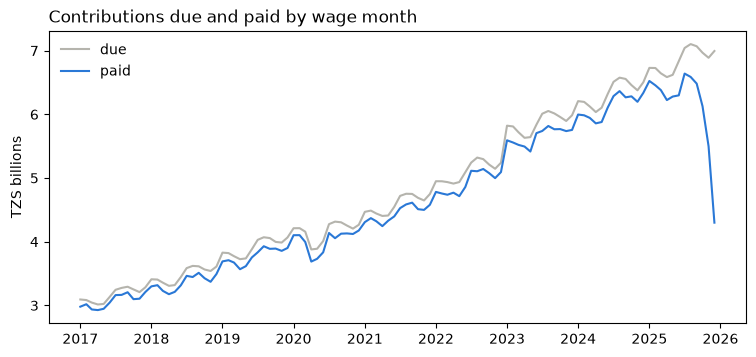

In [202]:
# Chart 1: contributions due and paid per wage month, in TZS billions.
monthly = contrib.groupby("period_start")[["contribution_due_tzs", "amount_paid_tzs"]].sum() / 1e9

plt.figure(figsize=(9, 3.8))
plt.plot(monthly.index, monthly["contribution_due_tzs"], color=GREY, label="due")
plt.plot(monthly.index, monthly["amount_paid_tzs"], color=BLUE, label="paid")
plt.title("Contributions due and paid by wage month", loc="left")
plt.ylabel("TZS billions")
plt.legend(frameon=False)
plt.savefig(FIGURES / "01_contributions_trend.png", dpi=130, bbox_inches="tight")
plt.show()

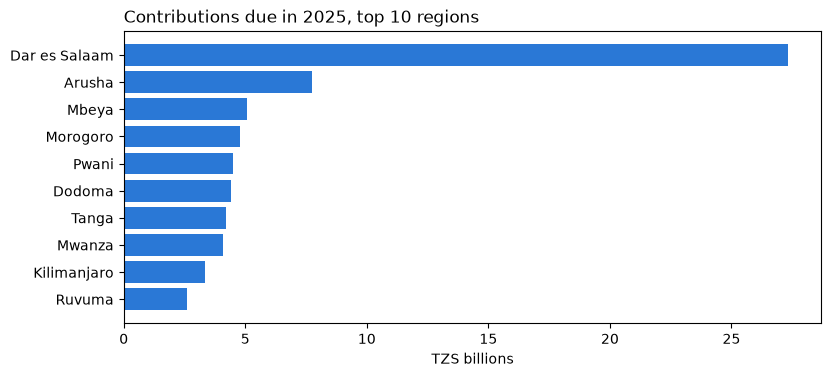

In [203]:
# Chart 2: contributions due in 2025 for the 10 largest regions.
# The region is on the employers table, so join it on first.
contrib_with_region = contrib.merge(employers[["employer_no", "region"]], on="employer_no", how="left")
in_2025 = contrib_with_region[contrib_with_region["period_start"] >= "2025-01-01"]

by_region = in_2025.groupby("region")["contribution_due_tzs"].sum() / 1e9
top_regions = by_region.sort_values().tail(10)

plt.figure(figsize=(9, 3.8))
plt.barh(top_regions.index, top_regions.values, color=BLUE)
plt.title("Contributions due in 2025, top 10 regions", loc="left")
plt.xlabel("TZS billions")
plt.savefig(FIGURES / "02_regions_2025.png", dpi=130, bbox_inches="tight")
plt.show()

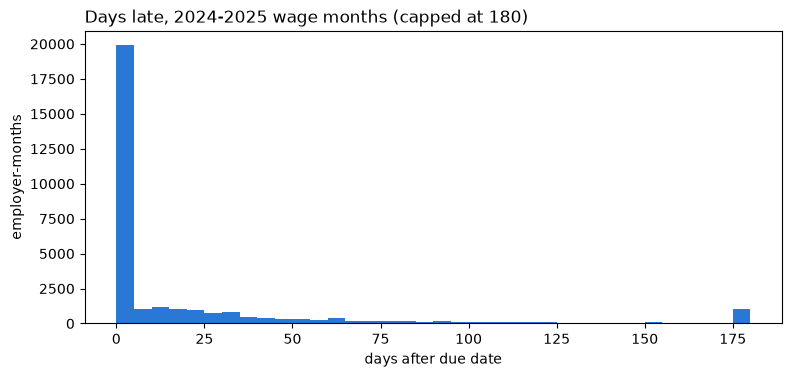

In [205]:
# Chart 3: how late are payments? A histogram of days late since 2024, capped at 180 days.
since_2024 = contrib[contrib["period_start"] >= "2024-01-01"]
days_late_capped = since_2024["days_late"].clip(upper=180)

plt.figure(figsize=(9, 3.8))
plt.hist(days_late_capped, bins=36, color=BLUE)
plt.title("Days late, 2024-2025 wage months (capped at 180)", loc="left")
plt.xlabel("days after due date")
plt.ylabel("employer-months")
plt.savefig(FIGURES / "03_days_late.png", dpi=130, bbox_inches="tight")
plt.show()

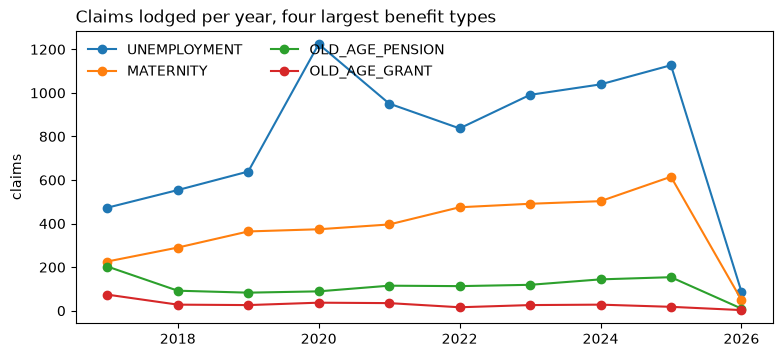

In [206]:
# Chart 4: claims per year for the four most common benefit types.
claims["year"] = claims["claim_date"].dt.year

# crosstab: one row per year, one column per benefit type, each cell = number of claims.
claims_per_year = pd.crosstab(claims["year"], claims["benefit_type"])

# The four benefit types with the most claims overall.
top4 = claims_per_year.sum().sort_values(ascending=False).index[:4]

plt.figure(figsize=(9, 3.8))
for benefit in top4:
    plt.plot(claims_per_year.index, claims_per_year[benefit], marker="o", label=benefit)
plt.title("Claims lodged per year, four largest benefit types", loc="left")
plt.ylabel("claims")
plt.legend(frameon=False, ncol=2)
plt.savefig(FIGURES / "04_claims_by_year.png", dpi=130, bbox_inches="tight")
plt.show()

### Theory: profiling as an early warning

In Lab 2 you profiled the tables by hand. In a pipeline, you profile them **automatically every run**, and keep the
result. The point isn't to read it every month. It's to compare it with last month's, because a big change usually
means something upstream changed:

- a column that was 2% empty is suddenly 40% empty: a source system stopped filling it in;
- a category column that had 26 regions now has 31: new spellings have crept in;
- the maximum amount jumps tenfold: a unit changed, or someone typed an extra zero.

A profile catches problems you didn't write a rule for. That's what makes it a good partner to the validation stage.

## 7. Profile stage: an automatic health check

A profile summarises every column in a table: type, missing share, and number of distinct values. Generating it
automatically each run means you'll spot a change (a column that's suddenly 40% empty) without having to go looking.

There are libraries that produce very detailed HTML profiles (`ydata-profiling` is popular). They're
useful but heavy. Three pandas methods give you most of the value and no extra dependency:

In [207]:
# For the members table: the type, the share missing, and the number of distinct values of each column.
members_profile = pd.DataFrame({
    "dtype": members.dtypes.astype(str),
    "missing_share": members.isna().mean().round(4),
    "distinct": members.nunique(),
})
members_profile

,dtype,missing_share,distinct
member_no,string,0.0000,60896
first_name,str,0.0000,63
surname,str,0.0000,44
gender,str,0.0120,2
date_of_birth,datetime64[us],0.0150,14632
nida_no,string,0.1181,53703
phone,string,0.0299,59122
region,str,0.0000,20
employer_no,string,0.0000,1400
employment_start,datetime64[us],0.0000,3447


In [208]:
# describe() adds min, median (50%) and max for the numeric columns.
members.describe()

,date_of_birth,employment_start,registration_date,contribution_months,exit_date,date_of_death,monthly_wage_tzs,age,tenure_years_current_employer
count,60102,61016,61016,61016.000000,28755,726,6.084000e+04,60102.000000,61016.000000
mean,1989-03-22 19:41:17.268643,2018-01-08 14:17:48.152615,2018-02-15 05:38:39.916087,78.504065,2022-03-09 03:47:36.338028,2022-04-27 02:26:46.611570,9.984778e+05,36.860407,6.223520
min,1957-07-03 00:00:00,1978-08-02 00:00:00,1978-08-04 00:00:00,0.000000,2017-01-01 00:00:00,2017-01-19 00:00:00,2.500000e+05,-9.400000,-0.100000
25%,1983-06-12 00:00:00,2016-01-02 00:00:00,2016-02-09 00:00:00,17.000000,2020-04-04 00:00:00,2020-08-01 18:00:00,4.640000e+05,29.700000,1.300000
50%,1990-05-22 12:00:00,2020-07-20 00:00:00,2020-08-13 00:00:00,49.000000,2022-04-25 00:00:00,2022-07-16 12:00:00,7.120000e+05,35.700000,3.600000
75%,1996-05-17 00:00:00,2023-06-15 00:00:00,2023-07-13 00:00:00,108.000000,2024-07-02 00:00:00,2024-05-08 12:00:00,1.169250e+06,42.600000,8.300000
max,2035-06-27 00:00:00,2025-12-28 00:00:00,2026-01-31 00:00:00,468.000000,2025-12-28 00:00:00,2026-01-27 00:00:00,1.690000e+07,68.600000,39.000000
std,NaN,NaN,NaN,83.916725,NaN,NaN,8.830949e+05,9.781300,7.027271


In [209]:
# Do the same for all four tables and stack them into one profile, with a "table" column saying which is which.
profiles = []
for table_name, table in [("employers", employers), ("members", members), ("contributions", contrib), ("claims", claims)]:
    table_profile = pd.DataFrame({
        "dtype": table.dtypes.astype(str),
        "missing_share": table.isna().mean().round(4),
        "distinct": table.nunique(),
    })
    table_profile["table"] = table_name
    profiles.append(table_profile)

profile = pd.concat(profiles)
profile = profile.rename_axis("column").reset_index()
profile.head(10)

,column,dtype,missing_share,distinct,table
0,employer_no,string,0.0000,1400,employers
1,employer_name,str,0.0000,1400,employers
2,sector,str,0.0086,13,employers
3,region,str,0.0000,20,employers
4,legal_form,str,0.0000,4,employers
5,tin,string,0.0000,1400,employers
6,registration_date,datetime64[us],0.0000,1312,employers
7,status,str,0.0000,2,employers
8,closure_date,datetime64[us],0.9293,51,employers
9,member_no,string,0.0000,60896,members


**Your turn (3).** Compare this profile with your manual findings from Lab 2. Which issues from your issues
log would this profile have caught on its own, and which needed a person's judgement? Write your answer in
the markdown cell below.

*Your answer here.*

> **Where we are.** You've built every stage of the pipeline in the notebook: load, clean, validate, transform,
> charts and profile. All that's left is to write the results to files, so other people (and tomorrow's notebooks)
> can use them.

## 8. Save the outputs

In [210]:
# The clean tables, as Parquet, in output/processed/.
PROCESSED = OUT / "processed"
PROCESSED.mkdir(exist_ok=True)

employers.to_parquet(PROCESSED / "employers.parquet", index=False)
members.to_parquet(PROCESSED / "members.parquet", index=False)
contrib.to_parquet(PROCESSED / "contributions.parquet", index=False)
claims.to_parquet(PROCESSED / "claims.parquet", index=False)

In [211]:
# The validation report and the profile, as CSV, so anyone can open them in Excel.
report.to_csv(OUT / "validation_report.csv", index=False)
profile.to_csv(OUT / "profile.csv", index=False)

# List everything in the output folder.
for path in sorted(OUT.rglob("*")):
    if path.is_file():
        print(path)

output/_test.csv
output/_test.parquet
output/figures/01_contributions_trend.png
output/figures/02_regions_2025.png
output/figures/03_days_late.png
output/figures/04_claims_by_year.png
output/processed/claims.parquet
output/processed/contributions.parquet
output/processed/employers.parquet
output/processed/members.parquet
output/profile.csv
output/validation_report.csv


### Theory: "fit" and "transform", the two halves of a preparation step

Models need numbers with no gaps. Preparing the data for a model usually means three steps:

- **Impute:** fill missing values, for example with the median of the column.
- **Scale:** put number columns on a common scale (mean 0, spread 1), so a wage in millions doesn't drown out an age in
  tens. This is called **standardising**.
- **Encode:** turn a text category like region into numbers. **One-hot encoding** makes one 0/1 column per region:
  `region_Arusha`, `region_Mwanza`, and so on.

Each of these steps first has to **learn** something from data (the median, the mean and spread, the list of regions),
and then **apply** what it learned. scikit-learn splits these into two methods:

- `fit(data)` learns the values;
- `transform(data)` applies them;
- `fit_transform(data)` does both in one go.

**Why the split matters.** When the model scores next month's claims, they must be prepared with **the same** medians
and region list it was trained with, not new ones worked out from next month's data. Fit once on the training data,
then only transform. A `Pipeline` bundles the steps so they always travel together. Day 2 builds on this directly.

## 9. A first look at scikit-learn: preprocessing as a pipeline

Tomorrow you'll build models, and every model needs its inputs prepared the same way at training time
and at prediction time. scikit-learn's `Pipeline` and `ColumnTransformer` bundle those steps so they
can't drift apart. Here's a preview on the members table.

In [212]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The columns to use.
numeric_columns = ["age", "monthly_wage_tzs", "contribution_months", "tenure_years_current_employer"]
category_columns = ["gender", "region"]

In [213]:
# Steps for number columns: fill gaps with the median, then rescale to mean 0 and spread 1.
numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Steps for text columns: fill gaps with the most common value, then one 0/1 column per value.
# min_frequency=200 groups rare regions together into one "infrequent" column.
category_steps = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=200)),
])

# Apply each set of steps to its own columns.
prep = ColumnTransformer([
    ("num", numeric_steps, numeric_columns),
    ("cat", category_steps, category_columns),
])

In [214]:
# fit_transform learns the medians, means and region list from the data, then applies them.
members_input = members[numeric_columns + category_columns]
X = prep.fit_transform(members_input)

print("Input:", members_input.shape, "-> model-ready matrix:", X.shape)
print(prep.get_feature_names_out()[:10])

Input: (61016, 6) -> model-ready matrix: (61016, 26)
['num__age' 'num__monthly_wage_tzs' 'num__contribution_months'
 'num__tenure_years_current_employer' 'cat__gender_F' 'cat__gender_M'
 'cat__region_Arusha' 'cat__region_Dar es Salaam' 'cat__region_Dodoma'
 'cat__region_Geita']


> **Where we are.** You now have a complete, working pipeline, and a preview of the preparation steps tomorrow's
> models need. But it all lives in notebook cells that have to be run by hand, in order.

### Theory: notebooks versus scripts

Notebooks are excellent for **learning and exploring**: you see each result as you go. They're poor for **running a
job every month**:

| | Notebook | Script (`.py` file) |
|---|---|---|
| Run it | click through cells in order | one command: `python src/fund_pipeline.py` |
| Schedule it at 2 a.m. | awkward | easy (Task Scheduler, cron, an orchestrator) |
| Run cells out of order by mistake | easy to do | impossible: it always runs top to bottom |
| Reuse a function elsewhere | copy and paste | `import` it |
| Review changes in Git | messy (outputs and metadata) | clean line-by-line differences |

The usual working pattern is the one you're following: explore and design in a notebook, then move the finished steps
into a script. The script has one **function** per stage, and a `main()` function that calls them in order.

**Command-line arguments.** `--raw` and `--out` let whoever runs the script choose the input and output folders without
editing the code. The `argparse` module reads them.

The imputer learns medians, the scaler learns means and standard deviations, the encoder learns the list
of regions. `fit` learns them once. After that, `transform` applies exactly the same values to any new data,
including next month's extract. On Day 2 you'll see why fitting these on the wrong data (the test set)
is a quiet way to fool yourself.

## 10. Move the code out of the notebook

Everything above works, but it lives in a notebook. Nobody can schedule a notebook to run at 2 a.m., and
nobody can import a function from it. The next cell writes the pipeline into a proper script,
`src/fund_pipeline.py`, that you can run from the terminal.

Read through it before you run it. It's the same steps you've just written, copied into one function per stage:
`load`, `clean_employers`, `clean_members`, `clean_contributions`, `clean_claims`, `validate`, `transform` and
`save_outputs`. At the bottom, `main()` calls them in order.

In [215]:
# Make the src folder at the project root (one level up from this notebook).
Path("../src").mkdir(parents=True, exist_ok=True)

In [217]:
%%writefile ../src/fund_pipeline.py
"""Fund data pipeline: load -> clean -> validate -> transform -> outputs.

Usage:
    python src/fund_pipeline.py --raw <folder with raw CSVs> --out <output folder>
"""
import argparse
from pathlib import Path

import matplotlib
matplotlib.use("Agg")          # draw charts to files, without opening a window
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SNAPSHOT = pd.Timestamp("2026-01-31")
WAGE_OUTLIER_LIMIT = 8         # flag wages this many times the employer median
REGION_FIX = {"dsm": "Dar es Salaam", "dar es salaam": "Dar es Salaam", "dar-es-salaam": "Dar es Salaam"}
PERSONAL_BENEFITS = ["MATERNITY", "UNEMPLOYMENT", "OLD_AGE_PENSION", "OLD_AGE_GRANT", "INVALIDITY_PENSION"]


# ---------- load ----------
def load(raw_dir):
    """Read the four raw CSV files, with ID columns as text and dates parsed."""
    raw_dir = Path(raw_dir)
    employers = pd.read_csv(raw_dir / "employers.csv",
                            dtype={"employer_no": "string", "tin": "string"},
                            parse_dates=["registration_date", "closure_date"])
    members = pd.read_csv(raw_dir / "members.csv",
                          dtype={"member_no": "string", "employer_no": "string", "nida_no": "string", "phone": "string"},
                          parse_dates=["date_of_birth", "employment_start", "registration_date", "exit_date", "date_of_death"])
    contrib = pd.read_csv(raw_dir / "contributions_monthly.csv",
                          dtype={"employer_no": "string", "period": "string", "members_reported": "int32"},
                          parse_dates=["due_date", "payment_date"])
    claims = pd.read_csv(raw_dir / "claims.csv",
                         dtype={"claim_no": "string", "member_no": "string"},
                         parse_dates=["claim_date", "decision_date"])
    print("loaded:", len(employers), "employers,", len(members), "members,",
          len(contrib), "contribution rows,", len(claims), "claims")
    return employers, members, contrib, claims


# ---------- clean ----------
def clean_region(region_column):
    """Trim spaces, fix the Dar es Salaam spellings, and title-case every other region."""
    region = region_column.str.strip().str.lower()
    region = region.replace(REGION_FIX)
    is_dar = region == "Dar es Salaam"
    region[~is_dar] = region[~is_dar].str.title()
    return region


def normalize_phone(phone):
    """Make every phone number look like +255712345678."""
    # Phone numbers come as "+255 712 345 678", "0712345678", ... Make them all "+255712345678".
    # Step 1: keep only the digits. The pattern \D means "any character that is not a digit".
    phone = phone.str.replace(r"\D", "", regex=True)

    # Step 2: a number starting with 0 is a local number: swap the leading 0 for the country code 255.
    phone = phone.str.replace(r"^0", "255", regex=True)

    # Step 3: put a + in front.
    return "+" + phone


def clean_employers(employers_raw):
    employers = employers_raw.copy()
    employers["employer_name"] = employers["employer_name"].str.strip()
    employers["region"] = clean_region(employers["region"])
    employers = employers.sort_values("employer_name")
    employers = employers.drop_duplicates(subset=["employer_no"], keep="first")
    return employers.reset_index(drop=True)


def clean_members(members_raw):
    members = members_raw.copy()
    members["region"] = clean_region(members["region"])

    gender = members["gender"].str.strip().str.upper().str[0]
    gender[~gender.isin(["F", "M"])] = np.nan
    members["gender"] = gender

    members["phone"] = normalize_phone(members["phone"])

    members = members.drop_duplicates(subset=["member_no"], keep="first").reset_index(drop=True)

    age_at_registration = (members["registration_date"] - members["date_of_birth"]).dt.days / 365.25
    members["flag_implausible_dob"] = age_at_registration < 15
    members.loc[members["flag_implausible_dob"], "date_of_birth"] = pd.NaT

    employer_median = members.groupby("employer_no")["monthly_wage_tzs"].transform("median")
    members["flag_wage_outlier"] = members["monthly_wage_tzs"] > WAGE_OUTLIER_LIMIT * employer_median
    return members


def clean_contributions(contrib_raw):
    contrib = contrib_raw.copy()

    # keep every row of employer-months with a reversal; drop exact duplicates elsewhere
    contrib["month_key"] = contrib["employer_no"] + "|" + contrib["period"]
    reversal_keys = contrib.loc[contrib["amount_paid_tzs"] < 0, "month_key"].unique()
    has_reversal = contrib["month_key"].isin(reversal_keys)
    contrib = pd.concat([contrib[has_reversal], contrib[~has_reversal].drop_duplicates()])

    # payment dates after the snapshot are typing errors
    contrib["future_date_fixed"] = contrib["payment_date"] > SNAPSHOT
    contrib.loc[contrib["future_date_fixed"], "payment_date"] = pd.NaT

    # one row per employer-month
    contrib = contrib.groupby(["employer_no", "period"], as_index=False).agg(
        members_reported=("members_reported", "first"),
        gross_wages_tzs=("gross_wages_tzs", "first"),
        contribution_due_tzs=("contribution_due_tzs", "first"),
        due_date=("due_date", "first"),
        amount_paid_tzs=("amount_paid_tzs", "sum"),
        payment_date=("payment_date", "min"),
        n_amounts=("amount_paid_tzs", "count"),
        n_postings=("amount_paid_tzs", "size"),
        future_date_fixed=("future_date_fixed", "max"),
    )
    contrib.loc[contrib["n_amounts"] == 0, "amount_paid_tzs"] = np.nan
    contrib = contrib.drop(columns=["n_amounts"])

    missing_wages = contrib["gross_wages_tzs"].isna()
    contrib.loc[missing_wages, "gross_wages_tzs"] = contrib.loc[missing_wages, "contribution_due_tzs"] / 0.20
    return contrib


def clean_claims(claims_raw):
    claims = claims_raw.copy()
    claims["benefit_type"] = claims["benefit_type"].str.strip().str.upper().str.replace(" ", "_")
    return claims


# ---------- validate ----------
def validate(employers, members, contrib, claims):
    """Count failures for each rule. Stop with an error if a hard rule fails."""
    claims_with_member = claims.merge(members[["member_no", "date_of_death", "gender"]], on="member_no", how="left")
    is_personal = claims_with_member["benefit_type"].isin(PERSONAL_BENEFITS)
    after_death = claims_with_member["claim_date"] > claims_with_member["date_of_death"]
    is_maternity = claims_with_member["benefit_type"] == "MATERNITY"
    is_funeral = claims["benefit_type"] == "FUNERAL_GRANT"

    report = pd.DataFrame(
        [
            ["member_no unique", "hard", members["member_no"].duplicated().sum()],
            ["employer-month unique", "hard", contrib.duplicated(subset=["employer_no", "period"]).sum()],
            ["claim_no unique", "hard", claims["claim_no"].duplicated().sum()],
            ["no negative net contributions", "hard", (contrib["amount_paid_tzs"] < 0).sum()],
            ["no payment dates after snapshot", "hard", (contrib["payment_date"] > SNAPSHOT).sum()],
            ["claim references a known member", "soft", (~claims["member_no"].isin(members["member_no"])).sum()],
            ["personal claim not after recorded death", "soft", (is_personal & after_death).sum()],
            ["maternity claim by female member", "soft", (is_maternity & (claims_with_member["gender"] == "M")).sum()],
            ["funeral grant equals TZS 500,000", "soft", (is_funeral & (claims["amount_claimed_tzs"] != 500_000)).sum()],
            ["paid not above due by more than 15%", "soft", (contrib["amount_paid_tzs"] > 1.15 * contrib["contribution_due_tzs"]).sum()],
        ],
        columns=["rule", "severity", "failures"],
    )
    report["status"] = "pass"
    report.loc[(report["failures"] > 0) & (report["severity"] == "soft"), "status"] = "review"
    report.loc[(report["failures"] > 0) & (report["severity"] == "hard"), "status"] = "FAIL"

    hard_failures = report[report["status"] == "FAIL"]
    if len(hard_failures) > 0:
        raise ValueError("Hard validation rules failed:\n" + hard_failures.to_string(index=False))
    print("validation: hard rules passed;", (report["status"] == "review").sum(), "soft rules to review")
    return report


# ---------- transform ----------
def transform(members, contrib):
    members = members.copy()
    members["age"] = ((SNAPSHOT - members["date_of_birth"]).dt.days / 365.25).round(1)
    end_date = members["exit_date"].fillna(SNAPSHOT)
    members["tenure_years_current_employer"] = ((end_date - members["employment_start"]).dt.days / 365.25).round(1)
    members["registered_late"] = (members["registration_date"] - members["employment_start"]).dt.days > 30

    contrib = contrib.copy()
    contrib["period_start"] = pd.to_datetime(contrib["period"] + "-01")
    settled_date = contrib["payment_date"].fillna(SNAPSHOT)
    contrib["days_late"] = (settled_date - contrib["due_date"]).dt.days.clip(lower=0)
    contrib["months_late"] = np.ceil(contrib["days_late"] / 30).astype(int)
    contrib["unpaid_tzs"] = (contrib["contribution_due_tzs"] - contrib["amount_paid_tzs"].fillna(0)).clip(lower=0)

    contrib["penalty_rate"] = 0.05
    new_rule = contrib["due_date"] >= pd.Timestamp("2025-10-01")
    contrib.loc[new_rule, "penalty_rate"] = 0.025
    contrib["penalty_estimate_tzs"] = contrib["contribution_due_tzs"] * contrib["penalty_rate"] * contrib["months_late"]
    cap = 0.5 * contrib["contribution_due_tzs"]
    over_cap = new_rule & (contrib["penalty_estimate_tzs"] > cap)
    contrib.loc[over_cap, "penalty_estimate_tzs"] = cap[over_cap]
    contrib["penalty_estimate_tzs"] = contrib["penalty_estimate_tzs"].round(-2)

    members_reported = contrib["members_reported"].replace(0, np.nan)
    contrib["contribution_per_member_tzs"] = (contrib["contribution_due_tzs"] / members_reported).round(0)
    return members, contrib


# ---------- outputs ----------
def make_profile(tables):
    """One row per column of every table: type, share missing, number of distinct values."""
    profiles = []
    for table_name, table in tables.items():
        table_profile = pd.DataFrame({
            "dtype": table.dtypes.astype(str),
            "missing_share": table.isna().mean().round(4),
            "distinct": table.nunique(),
        })
        table_profile["table"] = table_name
        profiles.append(table_profile)
    return pd.concat(profiles).rename_axis("column").reset_index()


def save_outputs(tables, report, out_dir):
    out_dir = Path(out_dir)
    (out_dir / "processed").mkdir(parents=True, exist_ok=True)
    (out_dir / "figures").mkdir(parents=True, exist_ok=True)

    for table_name, table in tables.items():
        table.to_parquet(out_dir / "processed" / f"{table_name}.parquet", index=False)
    report.to_csv(out_dir / "validation_report.csv", index=False)
    make_profile(tables).to_csv(out_dir / "profile.csv", index=False)

    contrib = tables["contributions"]
    monthly = contrib.groupby("period_start")[["contribution_due_tzs", "amount_paid_tzs"]].sum() / 1e9
    plt.figure(figsize=(9, 3.8))
    plt.plot(monthly.index, monthly["contribution_due_tzs"], color="#b5b4ad", label="due")
    plt.plot(monthly.index, monthly["amount_paid_tzs"], color="#2a78d6", label="paid")
    plt.title("Contributions due and paid by wage month", loc="left")
    plt.ylabel("TZS billions")
    plt.legend(frameon=False)
    plt.savefig(out_dir / "figures" / "01_contributions_trend.png", dpi=130, bbox_inches="tight")
    plt.close()
    print("done: outputs in", out_dir.resolve())


# ---------- run every stage in order ----------
def main(raw_dir, out_dir):
    employers_raw, members_raw, contrib_raw, claims_raw = load(raw_dir)

    employers = clean_employers(employers_raw)
    members = clean_members(members_raw)
    contrib = clean_contributions(contrib_raw)
    claims = clean_claims(claims_raw)

    report = validate(employers, members, contrib, claims)

    members, contrib = transform(members, contrib)

    tables = {"employers": employers, "members": members, "contributions": contrib, "claims": claims}
    save_outputs(tables, report, out_dir)


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Fund data pipeline")
    parser.add_argument("--raw", default="data/raw", help="folder containing the raw CSV files")
    parser.add_argument("--out", default="data/processed", help="folder for outputs")
    args = parser.parse_args()
    main(args.raw, args.out)

Overwriting src/fund_pipeline.py


## 11. Run it from the terminal

Open a terminal in this folder (with your environment active) and run:

```bash
python src/fund_pipeline.py --raw . --out run1
```

If you set up the Lab 1 project layout, the defaults already point at `data/raw` and `data/processed`, so
`python src/fund_pipeline.py` on its own is enough.

The next cell does the same thing from inside the notebook, using the same Python as this kernel, so you
can see the output here as well:

In [162]:
# sys.executable is the Python running this notebook. subprocess.run starts it as a separate program,
# exactly as if you had typed the command in a terminal. capture_output=True collects what it prints.
command = [sys.executable, "../src/fund_pipeline.py", "--raw", str(RAW), "--out", "run1"]
result = subprocess.run(command, capture_output=True, text=True)

print(result.stdout)
print(result.stderr)

loaded: 1408 employers, 61016 members, 127902 contribution rows, 13848 claims
validation: hard rules passed; 4 soft rules to review
done: outputs in /Users/daud.mabena/Documents/DUBAI/Training1910Labs/DAY1/Labs/work/fund-ai/notebooks/run1




### Theory: reproducibility, and how a checksum proves it

A result is **reproducible** if running the same code on the same input gives exactly the same output, every time, on
any machine. It sounds automatic, but many things quietly break it: a random choice with no fixed seed, rows that come
out in a different order, a library update that changes a default.

Comparing two output folders by eye is impossible. A **checksum** makes it easy. A checksum function such as SHA-256
reads every byte of a file and produces a short fingerprint:

```
members.parquet  ->  3f7a9c...e21b   (64 characters)
```

Change a single byte of the file and the fingerprint changes completely. So if two runs give files with the same
fingerprint, the files are identical, byte for byte. If one fingerprint differs, you know exactly which output changed.

## 12. Prove it's reproducible

Run the pipeline a second time into a different folder, then compare the outputs byte for byte using
**checksums**. A checksum (here SHA-256) is a short fingerprint of a file's contents: change one byte and the
fingerprint changes completely. If the code and the inputs are the same, the outputs must be the same.

In [163]:
# Second run, into run2.
command = [sys.executable, "../src/fund_pipeline.py", "--raw", str(RAW), "--out", "run2"]
result = subprocess.run(command, capture_output=True, text=True)
print(result.stdout)

loaded: 1408 employers, 61016 members, 127902 contribution rows, 13848 claims
validation: hard rules passed; 4 soft rules to review
done: outputs in /Users/daud.mabena/Documents/DUBAI/Training1910Labs/DAY1/Labs/work/fund-ai/notebooks/run2



In [164]:
def checksums(folder):
    """Return {file name: fingerprint} for every .parquet and .csv file in a folder."""
    folder = Path(folder)
    fingerprints = {}
    for path in sorted(folder.rglob("*")):
        if path.suffix in [".parquet", ".csv"]:
            file_bytes = path.read_bytes()
            fingerprint = hashlib.sha256(file_bytes).hexdigest()[:12]   # first 12 characters are enough to compare
            name = path.relative_to(folder).as_posix()
            fingerprints[name] = fingerprint
    return fingerprints

In [165]:
# Put the two runs side by side and compare.
comparison = pd.DataFrame({"run1": checksums("run1"), "run2": checksums("run2")})
comparison["same"] = comparison["run1"] == comparison["run2"]
comparison

,run1,run2,same
processed/claims.parquet,dfee7a51f852,dfee7a51f852,True
processed/contributions.parquet,6c498326b17a,6c498326b17a,True
processed/employers.parquet,b6b11a3fecfb,b6b11a3fecfb,True
processed/members.parquet,12d429adaa34,12d429adaa34,True
profile.csv,8657e83b261a,8657e83b261a,True
validation_report.csv,d374665ee8e3,d374665ee8e3,True


Every file matches. Now make a change to one rule and watch the checksum move. That's how you know a
change had an effect, and exactly which outputs it touched.

**Your turn (4).** In `src/fund_pipeline.py`, change `WAGE_OUTLIER_LIMIT = 8` to `WAGE_OUTLIER_LIMIT = 5`
(near the top). Run the pipeline into `run3` and compare its checksums with `run1`. Which files
changed? Which didn't, and why does that make sense? Change the limit back afterwards.

In [166]:
# Your code here

> **Where we are.** The pipeline runs from the terminal, and two runs give identical files. The last step is to put
> the code where your team can see and review it.

### Theory: branches and pull requests

In Git, a **branch** is a separate line of work. You make your changes on a branch (here `day1-pipeline`) so the main
version of the project stays working while you work.

A **pull request** (PR) is a request to merge your branch into the main one. It shows every line you changed, and
gives a colleague the chance to read and comment before the change goes in. Reviewing data code is about more than
spotting typos: the most important question is *"could this rule silently change or drop a real record?"*.

**Data never goes into Git.** Git is for code. Data files are large, change often, and here contain personal
information. That's why you check `git status` before committing, and why Day 3 brings in DVC for versioning data.

The final proof is the one from Lab 1. Recreate your environment from `requirements.txt` (or
`environment.yml`), then run the pipeline again. Same checksums means someone else, on another machine,
can reproduce your work. On Day 3 you'll take this further with DVC, which tracks the data files as well.

## 13. Commit, open a pull request, review

```bash
git switch -c day1-pipeline
git add src/fund_pipeline.py notebooks/
git status        # make sure no data or output files are staged
git commit -m "Add day 1 pipeline: load, clean, validate, transform, outputs"
git push -u origin day1-pipeline
```

Open a pull request and review it yourself before merging, the way a colleague would at work. Read the diff on the
Git server, not in your editor; you'll notice different things. A useful review for a data pipeline checks:

- Could any rule silently drop or change a real record? (Look hard at the contributions cleaning.)
- Are the hard rules really "stop everything" problems?
- Is anything hard-coded that will change: the snapshot date, the penalty rate, a file path?
- Would a new team member understand what the script prints?

## 14. Wrap-up: where this sits in the bigger picture

Look back at this morning's architecture slides. What you've built maps onto the same layers, just
smaller:

| Architecture layer | In your pipeline |
|---|---|
| Ingestion | `load` reading the source extracts, with types |
| Storage (raw zone) | `data/raw`, never modified |
| Processing | `clean_*`, `validate`, `transform` |
| Storage (curated zone) | Parquet files in `processed/` |
| Serving / reporting | charts, profile, validation report |
| Governance | hard/soft rules, flags instead of silent fixes, no data in Git |

The clean tables are what the rest of the week stands on. Tomorrow's claims risk model and member
segments start from exactly this kind of data.

---

## Answers to the "Your turn" exercises

**(1)** Checking the raw members table:

In [220]:
try:
    raw_duplicates = members_raw["member_no"].duplicated().sum()
    if raw_duplicates > 0:
        raise ValueError(f"Hard validation rule failed: member_no unique ({raw_duplicates} duplicates)")
    print("passed")
except ValueError as e:
    print(e)

Hard validation rule failed: member_no unique (120 duplicates)


**(2)** Months since exit:

In [168]:
# Whole months = (difference in years x 12) + difference in months.
years_between = SNAPSHOT.year - members["exit_date"].dt.year
months_between = SNAPSHOT.month - members["exit_date"].dt.month
members["months_since_exit"] = years_between * 12 + months_between

# Active members have no exit date, so their value stays empty.
members[members["exit_date"].notna()][["member_no", "status", "exit_date", "months_since_exit"]].head()

,member_no,status,exit_date,months_since_exit
1,159131551,INACTIVE,2021-04-11,57.0
2,253383084,INACTIVE,2025-02-28,11.0
4,468769855,INACTIVE,2025-05-18,8.0
5,122404483,INACTIVE,2018-03-14,94.0
6,364014563,INACTIVE,2024-01-03,24.0


**(3)** The profile catches anything visible in a single column: missing shares, strange minimums and
maximums (negative amounts, dates in the 2200s), and the number of distinct values (five spellings of
one region shows up as a higher-than-expected count). It can't catch anything that needs two tables or
some business knowledge: claims after a death, maternity claims against male records, the reversal
pattern, or a wage that's only implausible *compared with the rest of the same employer's staff*.

**(4)** Lower wage threshold:

In [218]:
# Read the script, change the limit, and save it.
script = Path("../src/fund_pipeline.py")
original_code = script.read_text()
changed_code = original_code.replace("WAGE_OUTLIER_LIMIT = 8", "WAGE_OUTLIER_LIMIT = 5")
script.write_text(changed_code)

# Run into run3.
subprocess.run([sys.executable, "../src/fund_pipeline.py", "--raw", str(RAW), "--out", "run3"], capture_output=True, text=True)

# Put the original code back.
script.write_text(original_code)
print("run3 finished; the script is back to WAGE_OUTLIER_LIMIT = 8")

run3 finished; the script is back to WAGE_OUTLIER_LIMIT = 8


In [219]:
comparison = pd.DataFrame({"run1": checksums("run1"), "run3": checksums("run3")})
comparison["same"] = comparison["run1"] == comparison["run3"]
comparison

,run1,run3,same
processed/claims.parquet,dfee7a51f852,dfee7a51f852,True
processed/contributions.parquet,6c498326b17a,6c498326b17a,True
processed/employers.parquet,b6b11a3fecfb,b6b11a3fecfb,True
processed/members.parquet,12d429adaa34,d9bf8a0d6324,False
profile.csv,8657e83b261a,8657e83b261a,True
validation_report.csv,d374665ee8e3,d374665ee8e3,True


Only `members.parquet` changes: more rows get `flag_wage_outlier = True`. The profile stays the same, because it
counts types, gaps and distinct values, and a True/False column has two distinct values either way. Contributions and
claims don't depend on that rule, so their files are identical. If they *had* changed, that would be a sign that
something is connected in a way you didn't expect.

## Looking back, looking ahead

**What you did today.** Across three labs you went from an empty laptop to a working data pipeline:

- **Lab 1:** an environment, a project layout and Git.
- **Lab 2:** you explored the raw data and wrote down every problem in an issues log.
- **Lab 3:** you turned the issues log into a pipeline: load with types, clean in a careful order, validate with hard
  and soft rules, add derived fields, draw standard charts, profile every table, save as Parquet, run it as a script,
  prove it's reproducible with checksums, and put it through review.

**The ideas to carry forward.**

- Raw data is never changed; every stage writes something new.
- Flag what you can't be sure of, and let a person decide.
- Fit preparation steps once, on training data, then only transform.
- If you can't reproduce a result, you can't trust it.

**Tomorrow (Day 2).** You'll use cleaned data to build your first machine learning models: a risk score that helps the
review team decide which claims to check first, and segments that group members and employers by behaviour. The
preparation steps from Section 9 become the first half of every model.